# Demonstrate the iterative path finder

We begin with the imports

In [ ]:
from os import chdir, path
thepath = path.abspath("../base")
chdir(thepath)

In [ ]:
# yaml processing file loading. 
import yaml
import numpy as np

from stl import mesh
import matplotlib.pyplot as plt
from matplotlib.cm import twilight


import iterative_pathfinder_centreline as ipf
from utils import return_source_targets, find_neighbours_with_knn


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


A mapping to the conduits and their number for easier access.

In [ ]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

A mapping of plotting keyword arguments for the various objects to be plotted. 

In [ ]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    pl = yaml.safe_load(f)
    f.close()

In [ ]:
skeleton_kwargs = pl["skeleton_kwargs"]
node_kwargs = pl["node_kwargs"]
ct_kwargs = pl["ct_kwargs"]
ct1_kwargs = pl["ct1_kwargs"]
ct2_kwargs = pl["ct2_kwargs"]
mesh_kwargs = pl["mesh_kwargs"]
start_kwargs = pl["start_kwargs"]
end_kwargs = pl["end_kwargs"]

In [ ]:
# set up the conduit name and ID. 
ID = 4
CONDUIT_NAME = conduit_map[ID]

thedir = f"../data/{ID}_{CONDUIT_NAME}"

In [ ]:
## import the mesh data. 
mesh_fp =  f"{thedir}//{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)

In [ ]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"

if not path.exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

In [ ]:
with open(f"{thedir}//{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [ ]:
ds = process_p["iterStepSize"]

In [ ]:
P1,nP1,P2,nP2 = return_source_targets(data, triangle_adjacency_matrix, eps = ds)

In [ ]:
L = 10 # guess a maximum line length
# if the iterative section minimiser has already been run, then, don't run and
# simply call it up again. 
iterative_ct_fp =  f"{thedir}//iterative/{CONDUIT_NAME}_centreline.txt"
sections_fp = f"{thedir}//iterative/sections2d"
sections3d_fp = f"{thedir}//iterative/sections3d"
iterative_vectors_fp = f"{thedir}//iterative/{CONDUIT_NAME}_vectors.txt") 


reverse = False # whether to start with P2 and end at P1, or the reverse.
keep_iterative = False

We can extract the iterative centreline from this process. 

In [33]:
iterative_ct = out_iterative["centreline"]

We can also plot the number of iterations needed each time to reach the chosen eps criterion for stopping. 
As well as the values of W and A which are computed at each step. We define the maximum number of iterations to be 20 and the stopping criterion to be 0.05 (5%).  

In [ ]:

progress_log = get_progress_log(out_iterative)
# number of optimisation iterations for each step of the path finder.
iterations = np.array([len(log)for log in out_iterative["logs"]]) 

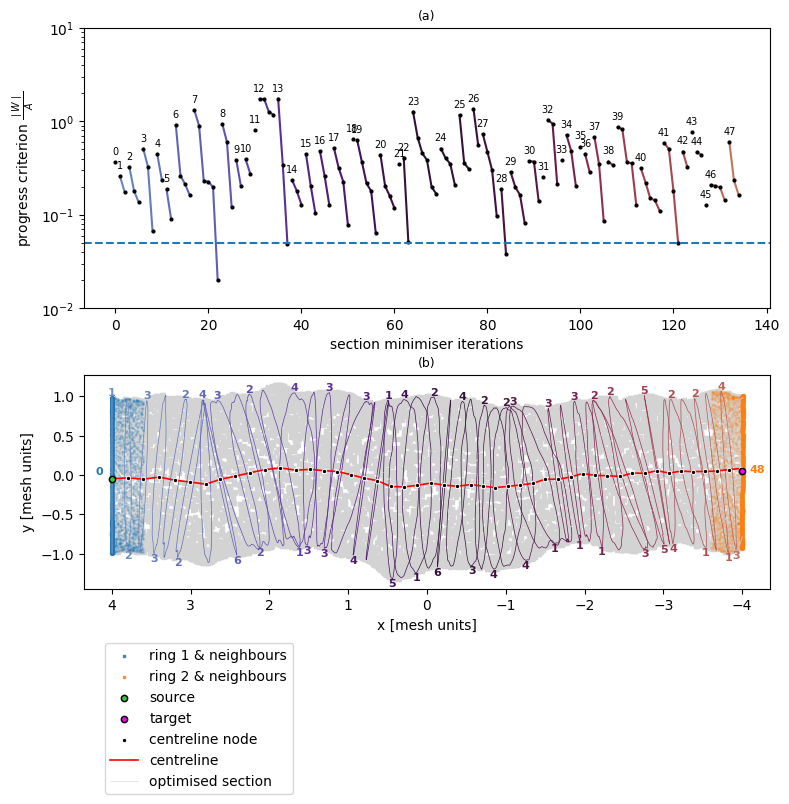

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (8, 8))


for k in np.unique(progress_log[:, 3]):
    thebool = progress_log[:, 3] == k
    thecolor = twilight(0.2+0.6*k/np.max(progress_log[:, 3]))

    ax1.scatter(progress_log[thebool, 4],
               progress_log[thebool, 0], 
               color = "k", 
               s = 4)
    
    ax1.semilogy(progress_log[thebool, 4],
                progress_log[thebool, 0], 
                color = thecolor, 
                zorder = -2)
    
    ax1.text(progress_log[thebool, 4][0], 
            progress_log[thebool, 0][0]*1.15, 
            f"{int(k):d}", va = "bottom", 
            ha="center", fontsize = 7)
    
ax1.set_xlabel("section minimiser iterations")
ax1.set_ylabel("progress criterion $\\frac{\\mid W\\mid}{A}$")
ax1.set_ylim(0.01, 10)
ax1.axhline(0.05, color = "C0", ls ="--")
ax1.set_title("(a)", fontsize = 9)

## bottom graph: the mesh
ax2.scatter(*data.centroids[::50, [0,1]].T, **mesh_kwargs)

## mesh P1 and P2 neighbours
ax2.scatter(*data.centroids[P1_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C0", edgecolors=None)
ax2.scatter(*data.centroids[P2_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C1", edgecolors=None)

## inlet and outlet rings
ax2.scatter(*ring1[:, [0,1]].T, label = "ring 1 & neighbours", alpha = 0.8, color ="C0", zorder = -1, s = 2, marker = "s")
ax2.scatter(*ring2[:, [0,1]].T, label = "ring 2 & neighbours", color = "C1", alpha = 0.8, zorder = -1, s =2, marker="s")

## inlet and outlet
ax2.scatter(*P1_in[[0,1]].T, **start_kwargs)
ax2.scatter(*P2_in[[0,1]].T, **end_kwargs)
ax2.legend()
ax2.set_aspect("equal")


ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs, label="centreline node")


for k, vertex_set in enumerate(out_iterative["vertices"]):
    thecolor = twilight(0.2+ 0.6*k/len(out_iterative["vertices"]))
    ## alternate between labelling the top or the bottom of a given section. 
    if k % 2 == 0:
        idx  = np.argmax(vertex_set[:, 1])
        va = "bottom"
    else: 
        idx = np.argmin(vertex_set[:, 1])
        va = "top"

    ## label the section 
    ax.text(*vertex_set[idx, [0,1]], 
            f"{iterations[k]}", fontsize = 8, 
            ha = "center", 
            va = va, 
            weight = "bold", 
            color =thecolor)
    
    ## plot the section
    ax.plot(*vertex_set[:, [0, 1]].T, 
            color = thecolor, 
            lw = 0.5)

## finally plot the centreline and one section for the legend.
ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs, label="centreline")
ax.plot(*out_iterative["vertices"][-1][:, [0, 1]].T, color = twilight(1), lw = 0.5, label="optimised section")

## label the inlet and outlet points.
ax.text(*out_iterative["centreline"][0, [0,1]]*1.015+0.05, 
        "0", 
        fontsize = 8, 
        color ="C0", 
        weight = "bold", 
        ha="right")

ax.text(*out_iterative["centreline"][-1, [0,1]]*1.015-0.05, 
        f"{len(out_iterative["vertices"])}", 
        fontsize = 8, 
        color ="C1", 
        ha = "left", 
        weight = "bold")


ax.set_xlim(4.35, -4.35)
ax.set_title("(b)", fontsize = 9)
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.legend(loc = "upper left", bbox_to_anchor= (0.02, -0.22))

plt.tight_layout()
plt.savefig(f"{thedir}//iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder_2.png", dpi = 300)
plt.savefig(f"{thedir}//iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder_2.pdf")

